# 01 · Data quality and exploratory analysis
**Synthetic portfolio case study · January–March 2026 · seed 2026**

This notebook establishes whether the data can answer the activation question. It validates provenance, exposes quarantined records, evaluates observation windows, independently reconstructs the funnel, and examines sample composition. The second notebook diagnoses product friction.

**Run order:** generator → validator → PostgreSQL loader → this notebook → notebook 02. Bundled SQL exports allow these notebooks to run without a database.

In [1]:
from pathlib import Path
import json, sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display, Markdown
from scipy.stats import norm
ROOT = Path.cwd() if (Path.cwd()/'data').exists() else Path.cwd().parent
assert (ROOT/'data/raw/manifest.json').exists(), 'Run from the project root or notebooks folder.'
EXPORT = ROOT/'data/dashboard_exports'
FIG = ROOT/'dashboards/screenshots'
FIG.mkdir(parents=True, exist_ok=True)
pd.set_option('display.max_columns', 18)
pd.set_option('display.float_format', lambda x: f'{x:,.4f}')
sns.set_theme(style='whitegrid', palette=['#635bff','#15a89c','#f1a43c','#e56b6f'])
plt.rcParams.update({'figure.dpi':120, 'axes.spines.top':False,'axes.spines.right':False})
def table(name):
    return pd.read_csv(EXPORT/f'{name}.csv', dtype={'signup_app_version':str,'app_version':str})
def savefig(name):
    plt.savefig(FIG/f'{name}.png', dpi=150, bbox_inches='tight')
    plt.show()
def wilson(k,n,z=1.959963984540054):
    k=np.asarray(k,dtype=float); n=np.asarray(n,dtype=float)
    p=k/n; d=1+z*z/n
    center=(p+z*z/(2*n))/d
    radius=z*np.sqrt(p*(1-p)/n+z*z/(4*n*n))/d
    return center-radius,center+radius
manifest=json.loads((ROOT/'data/raw/manifest.json').read_text())
cutoff=pd.Timestamp(manifest['observation_end_exclusive'])


## 1. Confirm source coverage and data grains
A session, a queue attempt, a game participation, and a user are different denominators. Keep those units explicit throughout the analysis.

In [2]:
sys.path.insert(0,str(ROOT/'src'))
from validate_data import read_tables
raw=read_tables(ROOT/'data/raw')
clean=read_tables(ROOT/'data/processed')
quality=json.loads((ROOT/'data/processed/validation_report.json').read_text())
coverage=pd.DataFrame([{'table':n,'raw_rows':len(raw[n]),'clean_rows':len(clean[n]),'columns':len(clean[n].columns)} for n in clean])
display(coverage)
print('Observation cutoff (exclusive):',cutoff)
print('Synthetic seed:',manifest['seed'])
assert quality['passed']


Observation cutoff (exclusive): 2026-04-01 00:00:00+00:00
Synthetic seed: 2026


,table,raw_rows,clean_rows,columns
0,users,10000,10000,5
1,sessions,57332,57332,6
2,events,281652,281502,7
3,matchmaking_attempts,45847,45847,8
4,game_participation,34384,34384,8


## 2. Verify raw-file provenance
Checksums prevent silent substitution or accidental edits to the source dataset. Regeneration with the documented seed and pinned dependencies reproduces these bytes.

In [3]:
import hashlib
hash_checks=[]
for name,meta in manifest['files'].items():
    actual=hashlib.sha256((ROOT/f'data/raw/{name}.csv').read_bytes()).hexdigest()
    hash_checks.append({'table':name,'hash_matches':actual==meta['sha256'],'rows_match':len(raw[name])==meta['rows']})
display(pd.DataFrame(hash_checks))
assert all(x['hash_matches'] and x['rows_match'] for x in hash_checks)


,table,hash_matches,rows_match
0,users,True,True
1,sessions,True,True
2,events,True,True
3,matchmaking_attempts,True,True
4,game_participation,True,True


## 3. Inspect rejected events and missingness
There are intentionally planted raw-event faults. Quarantine is explicit and reversible; raw input is preserved. Some rows violate multiple checks, so reason counts must not be added together. Optional game IDs, failure reasons, and terminal timestamps have legitimate nulls.

In [4]:
rejected=pd.read_csv(ROOT/'data/processed/rejected_events.csv')
display(pd.Series(quality['reason_counts'],name='violating_rows').to_frame())
display(rejected[['event_id','event_name','rejection_reason']].head(8))
missing=pd.concat([df.isna().mean().rename(name) for name,df in clean.items()],axis=1).T.fillna(0)
display(missing.loc[:,missing.max()>0])
assert quality['raw_event_rows']==quality['clean_event_rows']+len(rejected)
print(f"Quarantined {len(rejected):,} rows ({len(rejected)/len(raw['events']):.3%} of raw events).")


Quarantined 150 rows (0.053% of raw events).


,violating_rows
duplicate_event_id,100
outside_session,30
before_signup,30
session_owner_mismatch,20
unknown_user,20
attempt_owner_mismatch,10
game_owner_mismatch,7


,event_id,event_name,rejection_reason
0,BADUSER0013,game_joined,unknown_user;session_owner_mismatch;attempt_ow...
1,BADUSER0017,lobby_viewed,unknown_user;session_owner_mismatch;
2,BADUSER0004,game_started,unknown_user;session_owner_mismatch;attempt_ow...
3,BADUSER0000,session_started,unknown_user;session_owner_mismatch;
4,BADTIME0021,game_started,before_signup;outside_session;
5,E00136691,game_started,duplicate_event_id;
6,BADTIME0010,session_started,before_signup;outside_session;
7,BADTIME0007,game_completed,before_signup;outside_session;


,attempt_id,game_id,failure_reason,started_at,ended_at
users,0.0000,0.0000,0.0000,0.0000,0.0000
sessions,0.0000,0.0000,0.0000,0.0000,0.0000
events,0.4555,0.6591,0.0000,0.0000,0.0000
matchmaking_attempts,0.0000,0.2500,0.9605,0.0000,0.0000
game_participation,0.0000,0.0000,0.0000,0.1046,0.1046


## 4. Database integrity evidence
The eight SQL files were executed against PostgreSQL via PGlite. PostgreSQL primary/foreign keys reject broken relationships during loading; the following queries check temporal and semantic invariants beyond those constraints.

In [5]:
dq=table('dq_checks')
display(dq)
assert dq.violations.eq(0).all()
display(pd.DataFrame(quality['checks']))


,check_name,violations
0,event_before_signup,0
1,event_outside_observation,0
2,event_session_owner,0
3,event_outside_session,0
4,attempt_session_owner,0
5,game_attempt_mismatch,0
6,event_attempt_owner,0
7,completed_game_missing_event,0
8,invalid_game_event_order,0
9,missing_signup_event,0


,check,passed
0,users_unique_key,True
1,users_nonnull_key,True
2,sessions_unique_key,True
3,sessions_nonnull_key,True
4,sessions_valid_user,True
5,matchmaking_attempts_unique_key,True
6,matchmaking_attempts_nonnull_key,True
7,matchmaking_attempts_valid_user,True
8,game_participation_unique_key,True
9,game_participation_nonnull_key,True


## 5. Observation windows and censoring
Activation needs 24 hours of follow-up. D7 needs the complete seventh UTC calendar day after registration. Ineligible users are excluded from rate denominators, not converted into failures.

In [6]:
u=clean['users']; e=clean['events']; a=table('user_activation')
a['signup_at']=pd.to_datetime(a.signup_at,utc=True)
a['activation_eligible']=a.activation_eligible.astype(str).str.lower().isin(['true','t'])
a['d7_eligible']=a.d7_eligible.astype(str).str.lower().isin(['true','t'])
a['activated']=a.activated.astype(str).str.lower().isin(['true','t'])
assert a.activation_eligible.eq(a.signup_at+pd.Timedelta(hours=24)<=cutoff).all()
assert a.d7_eligible.eq(a.signup_at.dt.normalize()+pd.Timedelta(days=8)<=cutoff).all()
display(pd.DataFrame({'population':['All registrations','24h eligible','D7 eligible','Excluded: incomplete 24h','Excluded: incomplete D7'],
'users':[len(a),a.activation_eligible.sum(),a.d7_eligible.sum(),(~a.activation_eligible).sum(),(~a.d7_eligible).sum()]}))


,population,users
0,All registrations,10000
1,24h eligible,9897
2,D7 eligible,9263
3,Excluded: incomplete 24h,103
4,Excluded: incomplete D7,737


## 6. Independent ordered-path reconstruction
This state-machine implementation is deliberately different from the SQL lateral joins. It processes each user's event stream and keeps separate game states. It checks all users, not a convenient sample.

In [7]:
def reconstruct(rows,signup):
    onboard=False; lobby=False; joined=set(); started=set(); stage=1; completion=None
    for row in rows:
        t=row.event_timestamp
        if t<signup or t>=signup+pd.Timedelta(hours=24): continue
        name=row.event_name; gid=row.game_id
        if name=='onboarding_completed': onboard=True; stage=max(stage,2)
        elif name=='lobby_viewed' and onboard: lobby=True; stage=max(stage,3)
        elif name=='game_joined' and lobby: joined.add(gid); stage=max(stage,4)
        elif name=='game_started' and gid in joined: started.add(gid); stage=max(stage,5)
        elif name=='game_completed' and gid in started:
            stage=6
            if completion is None: completion=t
    return stage,completion
signup=u.set_index('user_id').signup_at
oracle=[]
for uid,grp in e.groupby('user_id',sort=False):
    stage,completion=reconstruct(grp.sort_values(['event_timestamp','event_id']).itertuples(index=False),signup[uid])
    oracle.append((uid,stage,completion))
oracle=pd.DataFrame(oracle,columns=['user_id','oracle_stage','oracle_completed_at'])
comparison=a.merge(oracle,on='user_id',validate='one_to_one')
assert comparison.furthest_stage.eq(comparison.oracle_stage).all()
assert comparison.activated.eq(comparison.oracle_completed_at.notna()).all()
print(f'Independent funnel reconstruction agrees for all {len(comparison):,} users.')


Independent funnel reconstruction agrees for all 10,000 users.


## 7. Adversarial metric fixtures
These cases protect the definition against common errors: cross-game stitching, selecting only the first game, counting an out-of-order event, and including a completion exactly at 24 hours.

In [8]:
from types import SimpleNamespace
base=pd.Timestamp('2026-01-01T00:00Z')
def fixture(seq):
    rows=[SimpleNamespace(event_timestamp=base+pd.Timedelta(seconds=t),event_name=n,game_id=g) for t,n,g in seq]
    return reconstruct(sorted(rows,key=lambda x:x.event_timestamp),base)[0]
prefix=[(1,'onboarding_completed',None),(2,'lobby_viewed',None)]
cases=[
('valid same game',prefix+[(3,'game_joined','A'),(4,'game_started','A'),(5,'game_completed','A')],6),
('cross-game completion',prefix+[(3,'game_joined','A'),(4,'game_started','A'),(5,'game_completed','B')],5),
('later game succeeds',prefix+[(3,'game_joined','A'),(4,'game_joined','B'),(5,'game_started','B'),(6,'game_completed','B')],6),
('completion at 24h excluded',prefix+[(3,'game_joined','A'),(4,'game_started','A'),(86400,'game_completed','A')],5),
('start before join excluded',prefix+[(3,'game_started','A'),(4,'game_joined','A'),(5,'game_completed','A')],4)]
fixture_results=pd.DataFrame([{'case':n,'expected':want,'actual':fixture(seq)} for n,seq,want in cases])
assert fixture_results.expected.eq(fixture_results.actual).all()
display(fixture_results)


,case,expected,actual
0,valid same game,6,6
1,cross-game completion,5,5
2,later game succeeds,6,6
3,completion at 24h excluded,5,5
4,start before join excluded,4,4


## 8. Acquisition mix and device composition
Channel comparisons are potentially confounded by hardware and intent. First show the composition instead of attributing all differences to channel quality.

device_tier,high,low,mid
acquisition_channel,,,
influencer,392,375,726
organic,802,815,1578
paid_social,563,1394,1449
referral,486,512,908


device_tier,high,low,mid
acquisition_channel,,,
influencer,0.2626,0.2512,0.4863
organic,0.2510,0.2551,0.4939
paid_social,0.1653,0.4093,0.4254
referral,0.2550,0.2686,0.4764


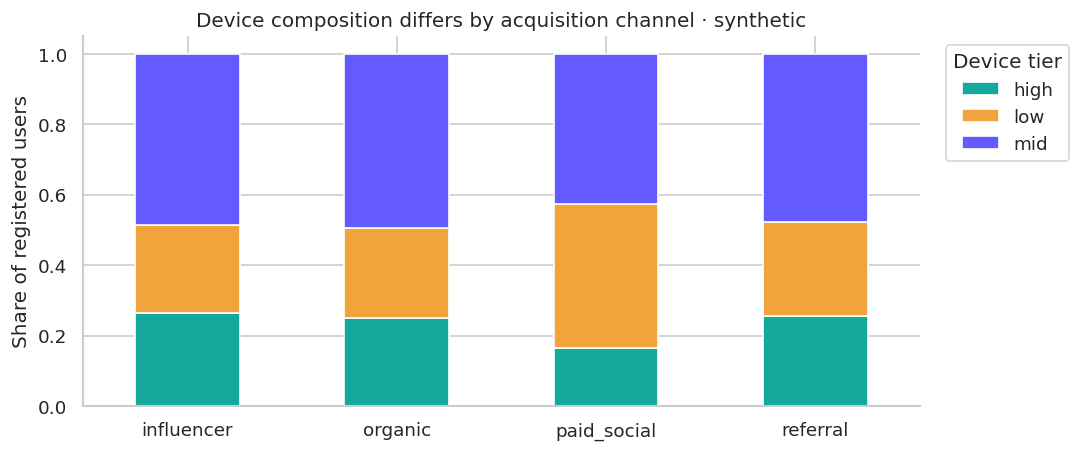

In [9]:
mix=pd.crosstab(u.acquisition_channel,u.device_tier)
display(mix)
display(mix.div(mix.sum(axis=1),axis=0))
fig,ax=plt.subplots(figsize=(9,4))
mix.div(mix.sum(axis=1),axis=0).plot.bar(stacked=True,ax=ax,color=['#15a89c','#f1a43c','#635bff'])
ax.set(ylabel='Share of registered users',xlabel='',title='Device composition differs by acquisition channel · synthetic')
ax.tick_params(axis='x',rotation=0); ax.legend(title='Device tier',bbox_to_anchor=(1.02,1))
savefig('01_channel_device_mix')


## 9. Time coverage and rollout exposure
Version 1.1 is introduced halfway through the simulation. A whole-period version comparison mixes product version and calendar time; the diagnostic notebook restricts comparisons to concurrent exposure.

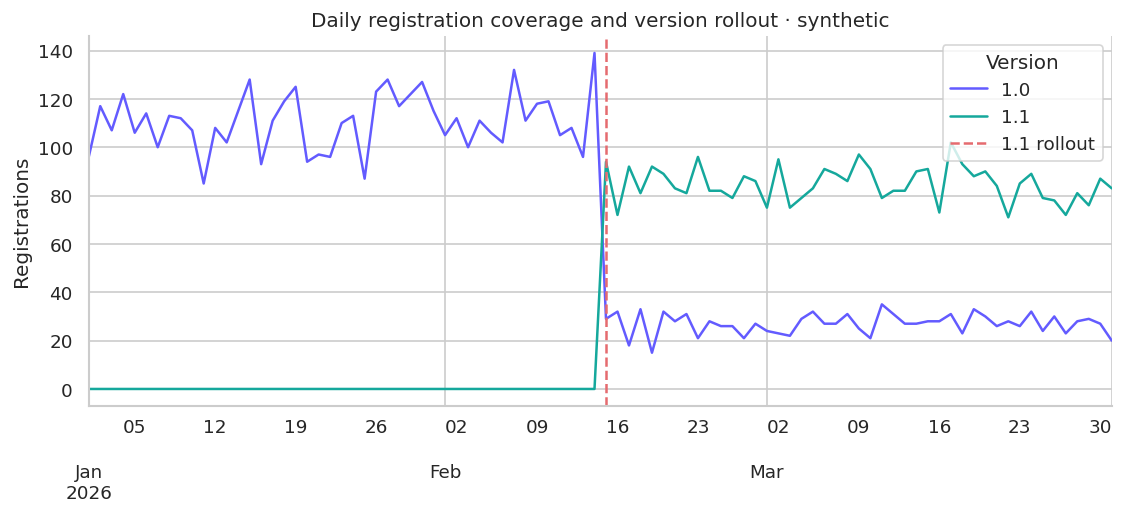

In [10]:
rollout=u.assign(day=u.signup_at.dt.floor('D')).groupby(['day','signup_app_version']).size().unstack(fill_value=0)
fig,ax=plt.subplots(figsize=(11,4)); rollout.plot(ax=ax)
ax.axvline(pd.Timestamp('2026-02-15',tz='UTC'),ls='--',color='#e56b6f',label='1.1 rollout')
ax.set(ylabel='Registrations',xlabel='',title='Daily registration coverage and version rollout · synthetic')
ax.legend(title='Version'); savefig('02_rollout_coverage')


## 10. Session behaviour and game outcomes
Heavy users produce more attempts and events. Use user-weighted outcomes for uncertainty estimates; do not treat every repeated attempt as an independent person.

,duration_minutes
count,"57,332.0000"
mean,6.6860
std,5.4807
min,0.3333
50%,5.9851
90%,14.9341
95%,16.0548
99%,17.1936
max,20.2147


,sessions_per_user
count,"10,000.0000"
mean,5.7332
std,2.7114
min,1.0000
50%,6.0000
90%,9.0000
95%,11.0000
99%,13.0000
max,17.0000


,participations
status,
completed,25466
exited,5321
not_started,3595
in_progress,2


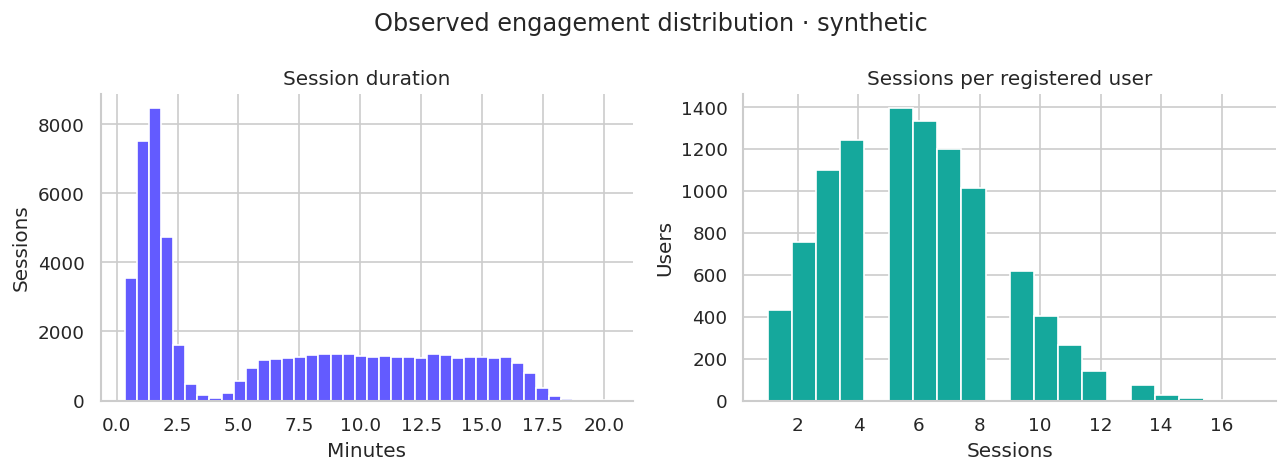

In [11]:
sessions=clean['sessions'].copy()
sessions['duration_minutes']=(sessions.session_end-sessions.session_start).dt.total_seconds()/60
sessions_per_user=sessions.groupby('user_id').size()
display(sessions.duration_minutes.describe(percentiles=[.5,.9,.95,.99]).to_frame())
display(sessions_per_user.describe(percentiles=[.5,.9,.95,.99]).to_frame('sessions_per_user'))
display(clean['game_participation'].completion_status.value_counts().rename_axis('status').to_frame('participations'))
fig,axes=plt.subplots(1,2,figsize=(11,4))
axes[0].hist(sessions.duration_minutes,bins=40,color='#635bff');axes[0].set(title='Session duration',xlabel='Minutes',ylabel='Sessions')
axes[1].hist(sessions_per_user,bins=20,color='#15a89c');axes[1].set(title='Sessions per registered user',xlabel='Sessions',ylabel='Users')
fig.suptitle('Observed engagement distribution · synthetic');fig.tight_layout();savefig('03_session_distributions')


## 11. Event volume is not a funnel
A game event can occur many times per user. Compare event counts with unique users before calculating a funnel; then use the ordered, time-bounded SQL table in notebook 02.

In [12]:
event_summary=e.groupby('event_name').agg(events=('event_id','size'),unique_users=('user_id','nunique')).sort_values('events',ascending=False)
event_summary['events_per_user']=event_summary.events/event_summary.unique_users
display(event_summary)
audit={'independent_user_checks':len(comparison),'funnel_mismatches':int(comparison.furthest_stage.ne(comparison.oracle_stage).sum()),'boundary_fixtures':len(fixture_results),'boundary_fixture_failures':int(fixture_results.expected.ne(fixture_results.actual).sum()),'raw_hash_checks_passed':True,'sql_dq_checks_passed':bool(dq.violations.eq(0).all())}
(ROOT/'data/processed/analysis_verification.json').write_text(json.dumps(audit,indent=2))
print('Saved independent analysis verification evidence.')


Saved independent analysis verification evidence.


,events,unique_users,events_per_user
event_name,,,
session_started,57332,10000,5.7332
lobby_viewed,51070,9786,5.2187
matchmaking_started,45847,9553,4.7992
game_joined,34384,9265,3.7112
game_started,30789,9083,3.3897
game_completed,25466,8640,2.9475
sign_up,10000,10000,1.0000
onboarding_completed,9830,9830,1.0000
queue_abandoned,9650,5729,1.6844


## Conclusion
The cleaned event stream reconciles to raw input, satisfies database integrity checks, and reproduces SQL activation classifications through an independent implementation. We can analyse funnel losses, but conclusions remain conditional on the documented synthetic mechanisms. Proceed to notebook 02 for diagnosis, prioritisation and an experiment proposal.